In [1]:
# ============================================================
# STEP 01.4 — PCA VISUALIZATION
# ASD MULTIMODAL PROJECT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

print("=" * 100)
print("STEP 01.4 — PCA VISUALIZATION")
print("=" * 100)

# ------------------------------------------------------------
# Resolve Project Root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while PROJECT_ROOT.name != "GAN-Enhanced-Multimodal-ASD-Screening":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("\nProject Root:")
print(PROJECT_ROOT)

# ------------------------------------------------------------
# Define Paths
# ------------------------------------------------------------

FUSION_DIR = PROJECT_ROOT / "05_multimodal_fusion"

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("\n✓ Directories configured successfully")

STEP 01.4 — PCA VISUALIZATION

Project Root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

✓ Directories configured successfully


In [2]:
# ============================================================
# LOAD FROZEN 32D EMBEDDINGS
# ============================================================

modalities = {
    "Genetic": {
        "embedding": "genetic_32d_normalized.npy",
        "target": "genetic_targets.npy"
    },
    "Behavioral": {
        "embedding": "behavioral_32d_normalized.npy",
        "target": "behavioral_targets.npy"
    },
    "Environmental": {
        "embedding": "environmental_32d_normalized.npy",
        "target": "environmental_targets.npy"
    }
}

data = {}

print("=" * 100)
print("LOADING EMBEDDINGS")
print("=" * 100)

for modality, files in modalities.items():

    X = np.load(FUSION_DIR / files["embedding"])
    y = np.load(FUSION_DIR / files["target"])

    data[modality] = {
        "X": X,
        "y": y
    }

    print(f"\n{modality}")
    print(f"Embedding shape: {X.shape}")
    print(f"Label shape    : {y.shape}")
    print(f"Classes        : {np.unique(y)}")

print("\n✓ All embeddings loaded successfully")

LOADING EMBEDDINGS

Genetic
Embedding shape: (116, 32)
Label shape    : (116,)
Classes        : [0 1]

Behavioral
Embedding shape: (880, 32)
Label shape    : (880,)
Classes        : [0 1]

Environmental
Embedding shape: (47768, 32)
Label shape    : (47768,)
Classes        : [0 1]

✓ All embeddings loaded successfully


In [3]:
# ============================================================
# CREATE VISUALIZATION DATASET
# ============================================================

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Environmental has many more samples.
# Limit it ONLY for visualization so it does not dominate PCA plots.

MAX_ENV_SAMPLES = 5000

visualization_data = {}

for modality, values in data.items():

    X = values["X"]
    y = values["y"]

    if modality == "Environmental" and len(X) > MAX_ENV_SAMPLES:

        indices = rng.choice(
            len(X),
            size=MAX_ENV_SAMPLES,
            replace=False
        )

        X_vis = X[indices]
        y_vis = y[indices]

        print(
            f"{modality}: sampled "
            f"{len(X_vis)} / {len(X)} samples for visualization"
        )

    else:

        X_vis = X
        y_vis = y

        print(
            f"{modality}: using all "
            f"{len(X_vis)} samples"
        )

    visualization_data[modality] = {
        "X": X_vis,
        "y": y_vis
    }

Genetic: using all 116 samples
Behavioral: using all 880 samples
Environmental: sampled 5000 / 47768 samples for visualization


In [4]:
# ============================================================
# COMBINE EMBEDDINGS
# ============================================================

X_list = []
y_list = []
modality_list = []

for modality, values in visualization_data.items():

    X = values["X"]
    y = values["y"]

    X_list.append(X)
    y_list.append(y)

    modality_list.extend([modality] * len(X))

X_combined = np.vstack(X_list)
y_combined = np.concatenate(y_list)
modality_labels = np.array(modality_list)

print("=" * 100)
print("COMBINED VISUALIZATION DATASET")
print("=" * 100)

print("\nCombined embedding shape:", X_combined.shape)
print("Combined label shape    :", y_combined.shape)
print("Embedding dimension     :", X_combined.shape[1])

print("\nSamples by modality:")

for modality in np.unique(modality_labels):
    count = np.sum(modality_labels == modality)
    print(f"{modality:<15}: {count}")

print("\nClass distribution:")

unique_classes, counts = np.unique(y_combined, return_counts=True)

for cls, count in zip(unique_classes, counts):
    print(f"Class {cls}: {count}")

COMBINED VISUALIZATION DATASET

Combined embedding shape: (5996, 32)
Combined label shape    : (5996,)
Embedding dimension     : 32

Samples by modality:
Behavioral     : 880
Environmental  : 5000
Genetic        : 116

Class distribution:
Class 0: 5245
Class 1: 751


In [5]:
# ============================================================
# APPLY PCA: 32D → 2D
# ============================================================

print("=" * 100)
print("RUNNING PCA")
print("=" * 100)

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_combined)

explained_variance = pca.explained_variance_ratio_

print("\nOriginal dimension:", X_combined.shape[1])
print("Reduced dimension :", X_pca.shape[1])

print("\nExplained Variance:")

print(
    f"PC1: {explained_variance[0] * 100:.2f}%"
)

print(
    f"PC2: {explained_variance[1] * 100:.2f}%"
)

print(
    f"Total: {explained_variance.sum() * 100:.2f}%"
)

print("\n✓ PCA completed successfully")

RUNNING PCA

Original dimension: 32
Reduced dimension : 2

Explained Variance:
PC1: 12.13%
PC2: 8.31%
Total: 20.44%

✓ PCA completed successfully


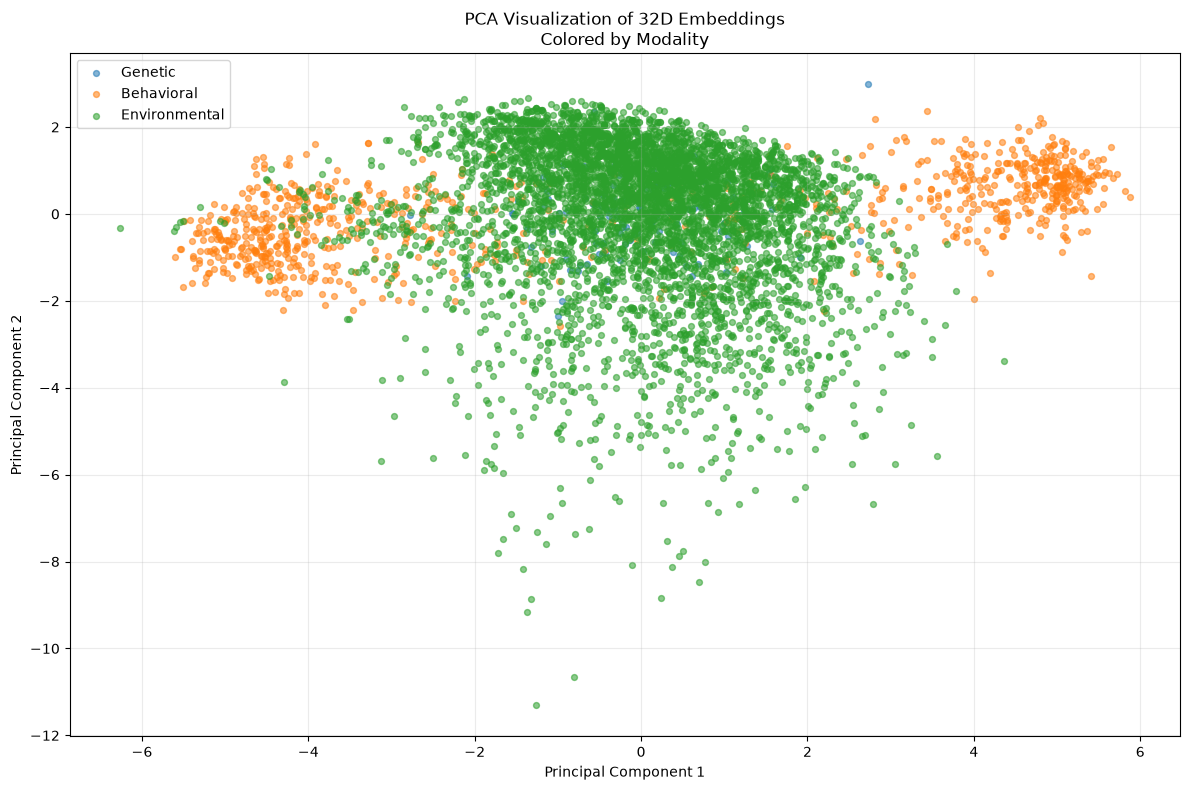


Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_04_pca_by_modality.png


In [6]:
# ============================================================
# PCA VISUALIZATION — COLOR BY MODALITY
# ============================================================

plt.figure(figsize=(12, 8))

for modality in ["Genetic", "Behavioral", "Environmental"]:

    mask = modality_labels == modality

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=modality,
        alpha=0.55,
        s=18
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "PCA Visualization of 32D Embeddings\nColored by Modality"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

output_path = (
    FIGURE_DIR
    / "01_04_pca_by_modality.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nSaved: {output_path}")

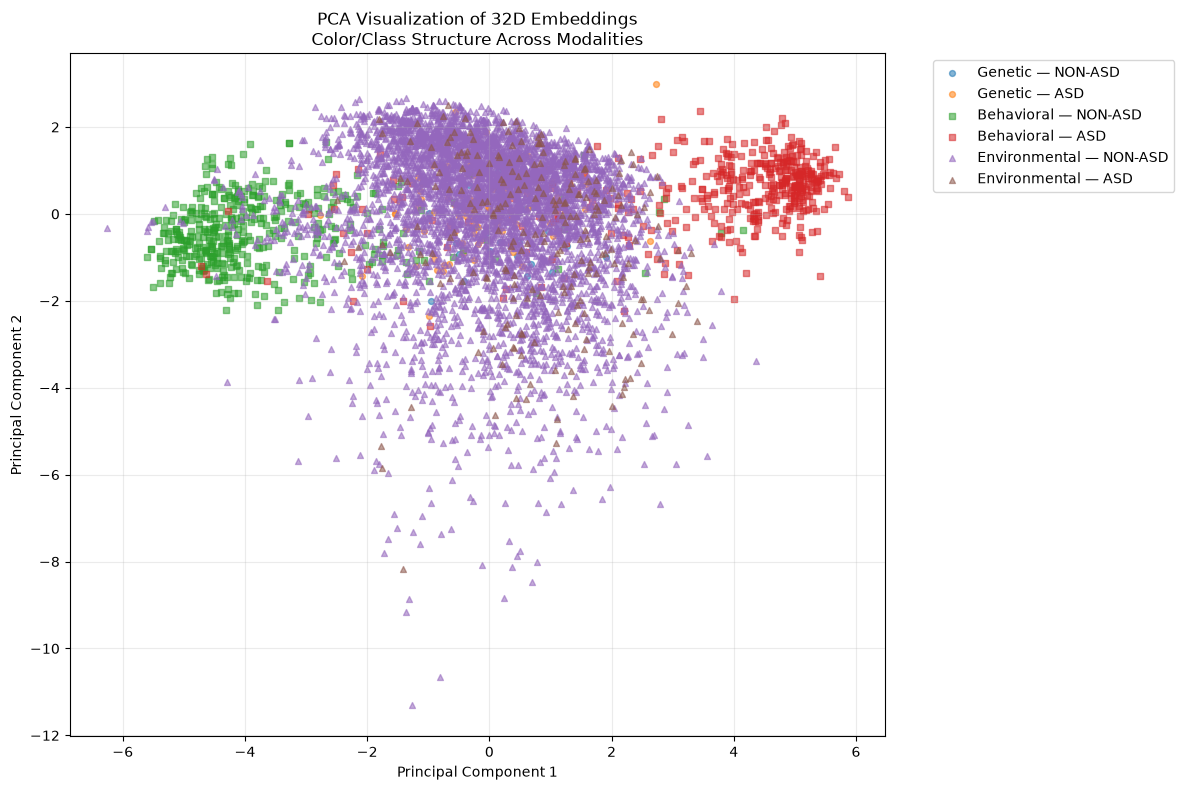


Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_04_pca_by_class_and_modality.png


In [7]:
# ============================================================
# PCA VISUALIZATION
# COLOR BY CLASS + MARKER BY MODALITY
# ============================================================

plt.figure(figsize=(12, 8))

markers = {
    "Genetic": "o",
    "Behavioral": "s",
    "Environmental": "^"
}

class_names = {
    0: "NON-ASD",
    1: "ASD"
}

for modality in ["Genetic", "Behavioral", "Environmental"]:

    modality_mask = modality_labels == modality

    for cls in [0, 1]:

        mask = modality_mask & (y_combined == cls)

        if np.sum(mask) == 0:
            continue

        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            marker=markers[modality],
            label=f"{modality} — {class_names[cls]}",
            alpha=0.55,
            s=18
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "PCA Visualization of 32D Embeddings\n"
    "Color/Class Structure Across Modalities"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.25)

plt.tight_layout()

output_path = (
    FIGURE_DIR
    / "01_04_pca_by_class_and_modality.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nSaved: {output_path}")

In [8]:
# ============================================================
# SAVE PCA SUMMARY REPORT
# ============================================================

pca_summary = pd.DataFrame({
    "Component": ["PC1", "PC2", "PC1 + PC2"],
    "Explained_Variance_Percentage": [
        explained_variance[0] * 100,
        explained_variance[1] * 100,
        explained_variance.sum() * 100
    ]
})

report_path = (
    REPORT_DIR
    / "01_04_pca_explained_variance.csv"
)

pca_summary.to_csv(
    report_path,
    index=False
)

print("=" * 100)
print("STEP 01.4 — PCA VISUALIZATION COMPLETED")
print("=" * 100)

print("\nExplained Variance Summary:")
display(pca_summary)

print("\nGenerated Figures:")
print("1. PCA colored by modality")
print("2. PCA colored by ASD/NON-ASD class and modality markers")

print("\nReport saved:")
print(report_path)

print("\n✓ Ready for Step 01.5 — t-SNE Visualization")

STEP 01.4 — PCA VISUALIZATION COMPLETED

Explained Variance Summary:


,Component,Explained_Variance_Percentage
0,PC1,12.134560
1,PC2,8.308959
2,PC1 + PC2,20.443518



Generated Figures:
1. PCA colored by modality
2. PCA colored by ASD/NON-ASD class and modality markers

Report saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_04_pca_explained_variance.csv

✓ Ready for Step 01.5 — t-SNE Visualization


In [10]:
# ============================================================
# STEP 01.4A — BALANCED CLASS-AWARE PCA VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.decomposition import PCA

# Reproducibility
RANDOM_STATE = 42

print("=" * 100)
print("STEP 01.4A — BALANCED CLASS-AWARE PCA VISUALIZATION")
print("=" * 100)

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

# If notebook is running inside the notebooks folder,
# move up to the project root safely
while PROJECT_ROOT.name != "GAN-Enhanced-Multimodal-ASD-Screening":
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("\nProject Root:")
print(PROJECT_ROOT)

print("\nFigure Directory:")
print(FIGURE_DIR)

print("\nReport Directory:")
print(REPORT_DIR)

STEP 01.4A — BALANCED CLASS-AWARE PCA VISUALIZATION

Project Root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Figure Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures

Report Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports


In [13]:
# ============================================================
# LOAD FROZEN 32D EMBEDDINGS FOR PCA ANALYSIS
# ============================================================

import numpy as np

# Paths to frozen baseline embeddings
FUSION_DIR = (
    PROJECT_ROOT
    / "05_multimodal_fusion"
)

# ------------------------------------------------------------
# Load Genetic
# ------------------------------------------------------------

genetic_embeddings = np.load(
    FUSION_DIR / "genetic_32d_normalized.npy"
)

genetic_labels = np.load(
    FUSION_DIR / "genetic_targets.npy"
)


# ------------------------------------------------------------
# Load Behavioral
# ------------------------------------------------------------

behavioral_embeddings = np.load(
    FUSION_DIR / "behavioral_32d_normalized.npy"
)

behavioral_labels = np.load(
    FUSION_DIR / "behavioral_targets.npy"
)


# ------------------------------------------------------------
# Load Environmental
# ------------------------------------------------------------

environmental_embeddings = np.load(
    FUSION_DIR / "environmental_32d_normalized.npy"
)

environmental_labels = np.load(
    FUSION_DIR / "environmental_targets.npy"
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 100)
print("FROZEN BASELINE EMBEDDINGS LOADED")
print("=" * 100)

print(f"\nGenetic Embeddings       : {genetic_embeddings.shape}")
print(f"Genetic Labels           : {genetic_labels.shape}")

print(f"\nBehavioral Embeddings    : {behavioral_embeddings.shape}")
print(f"Behavioral Labels        : {behavioral_labels.shape}")

print(f"\nEnvironmental Embeddings : {environmental_embeddings.shape}")
print(f"Environmental Labels     : {environmental_labels.shape}")

print("\n✓ All embeddings successfully loaded for PCA analysis.")

FROZEN BASELINE EMBEDDINGS LOADED

Genetic Embeddings       : (116, 32)
Genetic Labels           : (116,)

Behavioral Embeddings    : (880, 32)
Behavioral Labels        : (880,)

Environmental Embeddings : (47768, 32)
Environmental Labels     : (47768,)

✓ All embeddings successfully loaded for PCA analysis.


In [14]:
# ============================================================
# CHECK ORIGINAL CLASS DISTRIBUTIONS
# ============================================================

print("=" * 100)
print("ORIGINAL CLASS DISTRIBUTIONS")
print("=" * 100)

modalities = {
    "Genetic": {
        "embeddings": genetic_embeddings,
        "labels": genetic_labels
    },
    "Behavioral": {
        "embeddings": behavioral_embeddings,
        "labels": behavioral_labels
    },
    "Environmental": {
        "embeddings": environmental_embeddings,
        "labels": environmental_labels
    }
}

original_distribution = []

for modality, data in modalities.items():
    
    labels = data["labels"]
    
    unique, counts = np.unique(labels, return_counts=True)
    class_counts = dict(zip(unique, counts))
    
    original_distribution.append({
        "Modality": modality,
        "Class_0_Count": class_counts.get(0, 0),
        "Class_1_Count": class_counts.get(1, 0),
        "Total": len(labels)
    })
    
    print(f"\n{modality}")
    print("-" * 50)
    print(f"Class 0 : {class_counts.get(0, 0)}")
    print(f"Class 1 : {class_counts.get(1, 0)}")
    print(f"Total   : {len(labels)}")

original_distribution_df = pd.DataFrame(original_distribution)

print("\n" + "=" * 100)
print("ORIGINAL DISTRIBUTION TABLE")
print("=" * 100)

display(original_distribution_df)

ORIGINAL CLASS DISTRIBUTIONS

Genetic
--------------------------------------------------
Class 0 : 29
Class 1 : 87
Total   : 116

Behavioral
--------------------------------------------------
Class 0 : 439
Class 1 : 441
Total   : 880

Environmental
--------------------------------------------------
Class 0 : 45650
Class 1 : 2118
Total   : 47768

ORIGINAL DISTRIBUTION TABLE


,Modality,Class_0_Count,Class_1_Count,Total
0,Genetic,29,87,116
1,Behavioral,439,441,880
2,Environmental,45650,2118,47768


In [15]:
# ============================================================
# DETERMINE COMMON CLASS COUNTS
# ============================================================

print("=" * 100)
print("DETERMINING BALANCED CLASS COUNTS")
print("=" * 100)

classes = sorted(
    set(genetic_labels)
    .intersection(set(behavioral_labels))
    .intersection(set(environmental_labels))
)

balanced_counts = {}

for cls in classes:
    
    genetic_count = np.sum(genetic_labels == cls)
    behavioral_count = np.sum(behavioral_labels == cls)
    environmental_count = np.sum(environmental_labels == cls)
    
    min_count = min(
        genetic_count,
        behavioral_count,
        environmental_count
    )
    
    balanced_counts[cls] = min_count
    
    print(f"\nClass {cls}")
    print(f"  Genetic       : {genetic_count}")
    print(f"  Behavioral    : {behavioral_count}")
    print(f"  Environmental : {environmental_count}")
    print(f"  → Balanced count selected: {min_count}")

print("\n" + "=" * 100)
print("FINAL BALANCED SAMPLING STRATEGY")
print("=" * 100)

print(balanced_counts)

DETERMINING BALANCED CLASS COUNTS

Class 0
  Genetic       : 29
  Behavioral    : 439
  Environmental : 45650
  → Balanced count selected: 29

Class 1
  Genetic       : 87
  Behavioral    : 441
  Environmental : 2118
  → Balanced count selected: 87

FINAL BALANCED SAMPLING STRATEGY
{np.int64(0): np.int64(29), np.int64(1): np.int64(87)}


In [16]:
# ============================================================
# CLASS-AWARE BALANCED SAMPLING
# ============================================================

rng = np.random.default_rng(RANDOM_STATE)

def stratified_balanced_sample(embeddings, labels, target_counts):
    """
    Randomly samples equal class counts according to target_counts.
    """
    
    selected_indices = []
    
    for cls, target_count in target_counts.items():
        
        class_indices = np.where(labels == cls)[0]
        
        if len(class_indices) < target_count:
            raise ValueError(
                f"Not enough samples for class {cls}. "
                f"Available: {len(class_indices)}, "
                f"Requested: {target_count}"
            )
        
        sampled_indices = rng.choice(
            class_indices,
            size=target_count,
            replace=False
        )
        
        selected_indices.extend(sampled_indices)
    
    selected_indices = np.array(selected_indices)
    
    # Shuffle final selected indices
    rng.shuffle(selected_indices)
    
    return (
        embeddings[selected_indices],
        labels[selected_indices]
    )


# ------------------------------------------------------------
# Apply sampling to each modality
# ------------------------------------------------------------

balanced_genetic_embeddings, balanced_genetic_labels = (
    stratified_balanced_sample(
        genetic_embeddings,
        genetic_labels,
        balanced_counts
    )
)

balanced_behavioral_embeddings, balanced_behavioral_labels = (
    stratified_balanced_sample(
        behavioral_embeddings,
        behavioral_labels,
        balanced_counts
    )
)

balanced_environmental_embeddings, balanced_environmental_labels = (
    stratified_balanced_sample(
        environmental_embeddings,
        environmental_labels,
        balanced_counts
    )
)


print("=" * 100)
print("BALANCED SAMPLING COMPLETED")
print("=" * 100)

for name, labels in [
    ("Genetic", balanced_genetic_labels),
    ("Behavioral", balanced_behavioral_labels),
    ("Environmental", balanced_environmental_labels)
]:
    
    unique, counts = np.unique(labels, return_counts=True)
    
    print(f"\n{name}")
    print(f"Total samples: {len(labels)}")
    
    for cls, count in zip(unique, counts):
        print(f"Class {cls}: {count}")

BALANCED SAMPLING COMPLETED

Genetic
Total samples: 116
Class 0: 29
Class 1: 87

Behavioral
Total samples: 116
Class 0: 29
Class 1: 87

Environmental
Total samples: 116
Class 0: 29
Class 1: 87


In [17]:
# ============================================================
# COMBINE BALANCED REPRESENTATIONS
# ============================================================

X_balanced = np.vstack([
    balanced_genetic_embeddings,
    balanced_behavioral_embeddings,
    balanced_environmental_embeddings
])

y_balanced = np.concatenate([
    balanced_genetic_labels,
    balanced_behavioral_labels,
    balanced_environmental_labels
])

modality_balanced = np.array(
    ["Genetic"] * len(balanced_genetic_embeddings)
    + ["Behavioral"] * len(balanced_behavioral_embeddings)
    + ["Environmental"] * len(balanced_environmental_embeddings)
)

print("=" * 100)
print("BALANCED COMBINED DATASET")
print("=" * 100)

print(f"Combined embedding shape : {X_balanced.shape}")
print(f"Combined label shape     : {y_balanced.shape}")
print(f"Total samples            : {len(X_balanced)}")
print(f"Embedding dimension      : {X_balanced.shape[1]}")


# ============================================================
# PCA
# ============================================================

pca_balanced = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_balanced_pca = pca_balanced.fit_transform(X_balanced)

explained_variance = (
    pca_balanced.explained_variance_ratio_ * 100
)

print("\n" + "=" * 100)
print("BALANCED PCA EXPLAINED VARIANCE")
print("=" * 100)

print(f"PC1: {explained_variance[0]:.4f}%")
print(f"PC2: {explained_variance[1]:.4f}%")
print(
    f"PC1 + PC2: {explained_variance.sum():.4f}%"
)

BALANCED COMBINED DATASET
Combined embedding shape : (348, 32)
Combined label shape     : (348,)
Total samples            : 348
Embedding dimension      : 32

BALANCED PCA EXPLAINED VARIANCE
PC1: 20.3330%
PC2: 7.9157%
PC1 + PC2: 28.2487%


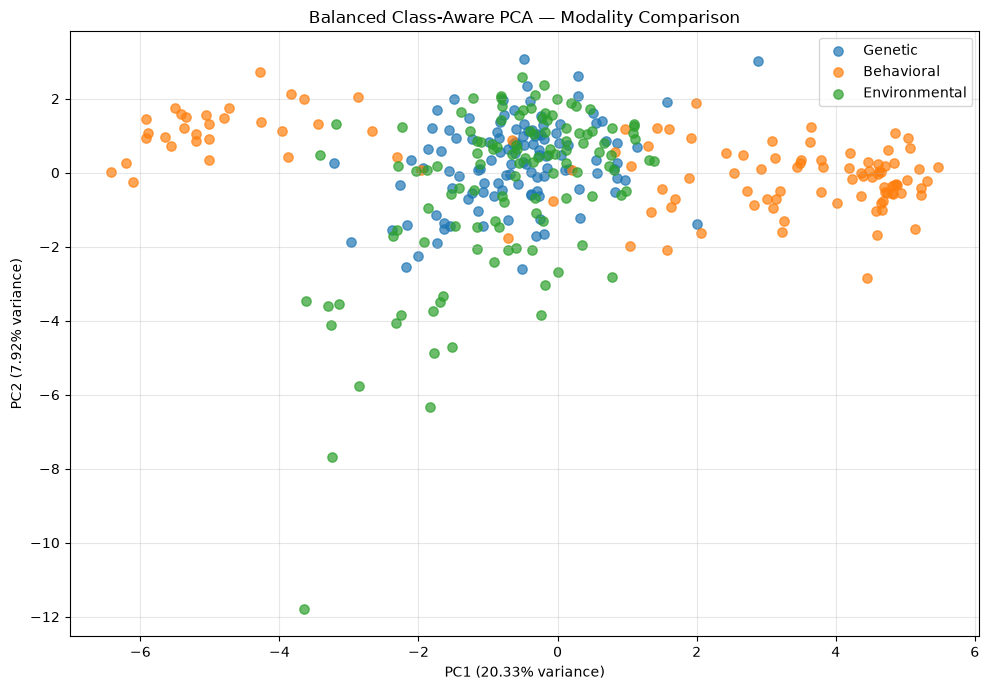


Figure saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_04A_balanced_pca_by_modality.png


In [18]:
# ============================================================
# BALANCED PCA — COLORED BY MODALITY
# ============================================================

plt.figure(figsize=(10, 7))

for modality in ["Genetic", "Behavioral", "Environmental"]:
    
    mask = modality_balanced == modality
    
    plt.scatter(
        X_balanced_pca[mask, 0],
        X_balanced_pca[mask, 1],
        label=modality,
        alpha=0.7,
        s=45
    )

plt.xlabel(
    f"PC1 ({explained_variance[0]:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({explained_variance[1]:.2f}% variance)"
)

plt.title(
    "Balanced Class-Aware PCA — Modality Comparison"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

output_path = (
    FIGURE_DIR
    / "01_04A_balanced_pca_by_modality.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nFigure saved to:\n{output_path}")

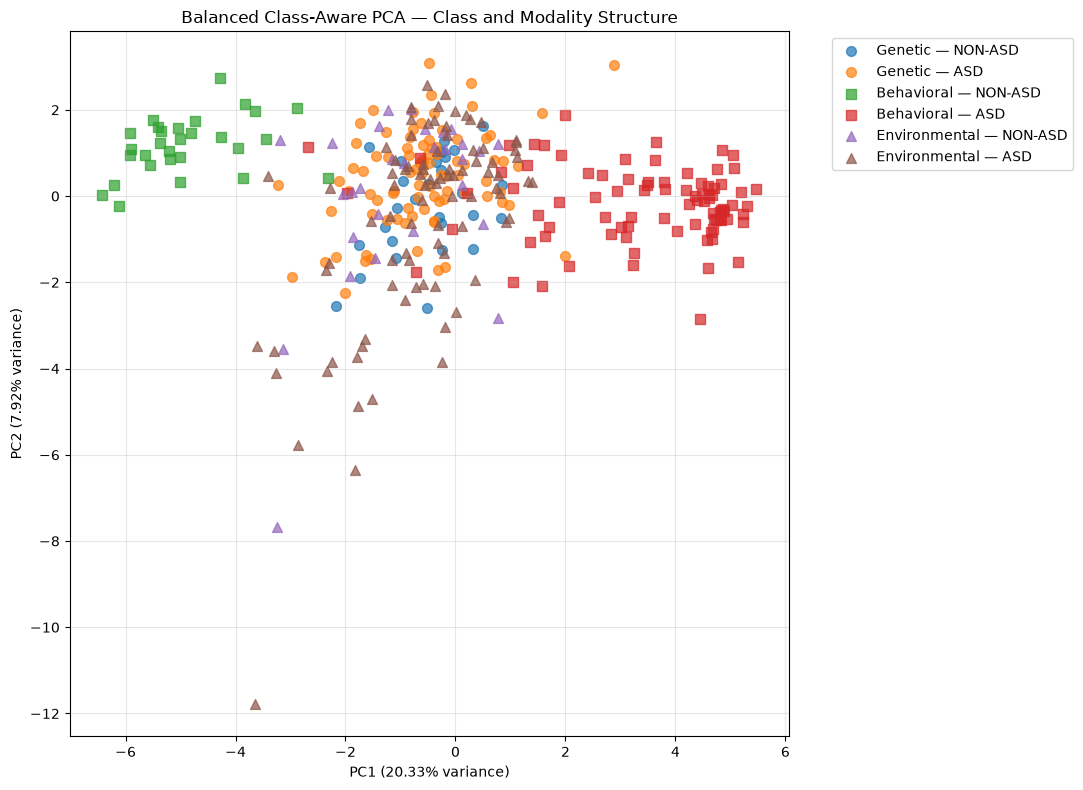


Figure saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_04A_balanced_pca_class_and_modality.png


In [19]:
# ============================================================
# BALANCED PCA — CLASS + MODALITY
# ============================================================

plt.figure(figsize=(11, 8))

markers = {
    "Genetic": "o",
    "Behavioral": "s",
    "Environmental": "^"
}

for modality in ["Genetic", "Behavioral", "Environmental"]:
    
    for cls in sorted(np.unique(y_balanced)):
        
        mask = (
            (modality_balanced == modality)
            & (y_balanced == cls)
        )
        
        class_name = (
            "NON-ASD" if cls == 0 else "ASD"
        )
        
        plt.scatter(
            X_balanced_pca[mask, 0],
            X_balanced_pca[mask, 1],
            marker=markers[modality],
            alpha=0.7,
            s=50,
            label=f"{modality} — {class_name}"
        )

plt.xlabel(
    f"PC1 ({explained_variance[0]:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({explained_variance[1]:.2f}% variance)"
)

plt.title(
    "Balanced Class-Aware PCA — Class and Modality Structure"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.tight_layout()

output_path = (
    FIGURE_DIR
    / "01_04A_balanced_pca_class_and_modality.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nFigure saved to:\n{output_path}")

In [20]:
# ============================================================
# BALANCED PCA REPORT
# ============================================================

balanced_summary = []

for modality in ["Genetic", "Behavioral", "Environmental"]:
    
    mask = modality_balanced == modality
    
    modality_labels = y_balanced[mask]
    
    class_0_count = np.sum(modality_labels == 0)
    class_1_count = np.sum(modality_labels == 1)
    
    balanced_summary.append({
        "Modality": modality,
        "Class_0_Count": class_0_count,
        "Class_1_Count": class_1_count,
        "Total_Samples": len(modality_labels)
    })

balanced_summary_df = pd.DataFrame(balanced_summary)

print("=" * 100)
print("BALANCED PCA SAMPLING SUMMARY")
print("=" * 100)

display(balanced_summary_df)


# Explained variance report

variance_df = pd.DataFrame({
    "Component": [
        "PC1",
        "PC2",
        "PC1 + PC2"
    ],
    "Explained_Variance_Percentage": [
        explained_variance[0],
        explained_variance[1],
        explained_variance.sum()
    ]
})

print("\n" + "=" * 100)
print("EXPLAINED VARIANCE")
print("=" * 100)

display(variance_df)


# Save reports

sampling_report_path = (
    REPORT_DIR
    / "01_04A_balanced_pca_sampling_summary.csv"
)

variance_report_path = (
    REPORT_DIR
    / "01_04A_balanced_pca_explained_variance.csv"
)

balanced_summary_df.to_csv(
    sampling_report_path,
    index=False
)

variance_df.to_csv(
    variance_report_path,
    index=False
)

print("\n" + "=" * 100)
print("✓ STEP 01.4A — BALANCED CLASS-AWARE PCA COMPLETED")
print("=" * 100)

print("\nBalanced Sampling:")
print(
    "Each modality contains identical class counts "
    "for fair knowledge-level visualization."
)

print("\nTotal samples per modality:")
print(len(balanced_genetic_labels))

print("\nTotal combined samples:")
print(len(X_balanced))

print("\nExplained Variance:")
print(f"PC1: {explained_variance[0]:.4f}%")
print(f"PC2: {explained_variance[1]:.4f}%")
print(f"Total: {explained_variance.sum():.4f}%")

print("\nReports saved:")
print(sampling_report_path)
print(variance_report_path)

print("\nNext Step:")
print("01.5 — t-SNE Visualization")

BALANCED PCA SAMPLING SUMMARY


,Modality,Class_0_Count,Class_1_Count,Total_Samples
0,Genetic,29,87,116
1,Behavioral,29,87,116
2,Environmental,29,87,116



EXPLAINED VARIANCE


,Component,Explained_Variance_Percentage
0,PC1,20.333021
1,PC2,7.915724
2,PC1 + PC2,28.248745



✓ STEP 01.4A — BALANCED CLASS-AWARE PCA COMPLETED

Balanced Sampling:
Each modality contains identical class counts for fair knowledge-level visualization.

Total samples per modality:
116

Total combined samples:
348

Explained Variance:
PC1: 20.3330%
PC2: 7.9157%
Total: 28.2487%

Reports saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_04A_balanced_pca_sampling_summary.csv
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_04A_balanced_pca_explained_variance.csv

Next Step:
01.5 — t-SNE Visualization
